In [2]:
!mamba install pandas numpy scikit-learn

mambajs 0.21.4

Specs: xeus-python, numpy, matplotlib, pillow, ipywidgets>=8.1.6, ipyleaflet, scipy, pandas, scikit-learn
Channels: emscripten-forge-4x, conda-forge

Solving environment...
Solving took 4.461 seconds
  Name                Version     Build                Channel
----------------------------------------------------------------------------
+ brotli-python       1.2.0       py313h8faef1e_3      emscripten-forge-4x
+ certifi             2026.10.23  pyhd8ed1ab_0         conda-forge
+ charset-normalizer  3.5.1       pyhd8ed1ab_0         conda-forge
+ idna                3.20        pyh5ded981_0         conda-forge
+ joblib              1.6.0       py313h57e9779_0      emscripten-forge-4x
+ narwhals            2.28.0      pyh5ded981_0         conda-forge
+ pandas              3.1.0       np23py313h124dbc7_0  emscripten-forge-4x
+ pysocks             1.7.1       py313h1804a44_3      emscripten-forge-4x
+ requests            2.34.2      pyhcf101f3_0         conda-forge
+ scikit-

In [3]:
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC

from sklearn.metrics import accuracy_score
from sklearn.metrics import confusion_matrix
from sklearn.metrics import classification_report

In [4]:
df = pd.read_csv("emails.csv")

print("First 5 Rows:")
display(df.head())

print("Dataset Shape:", df.shape)

First 5 Rows:


,Email No.,the,to,ect,and,for,of,a,you,hou,...,connevey,jay,valued,lay,infrastructure,military,allowing,ff,dry,Prediction
0,Email 1,0,0,1,0,0,0,2,0,0,...,0,0,0,0,0,0,0,0,0,0
1,Email 2,8,13,24,6,6,2,102,1,27,...,0,0,0,0,0,0,0,1,0,0
2,Email 3,0,0,1,0,0,0,8,0,0,...,0,0,0,0,0,0,0,0,0,0
3,Email 4,0,5,22,0,5,1,51,2,10,...,0,0,0,0,0,0,0,0,0,0
4,Email 5,7,6,17,1,5,2,57,0,9,...,0,0,0,0,0,0,0,1,0,0


Dataset Shape: (5172, 3002)


In [3]:
print("Missing Values:")
print(df.isnull().sum().sum())

df = df.dropna()

df = df.drop_duplicates()

print("After Preprocessing:", df.shape)

Missing Values:


In [5]:
X = df.drop(['Email No.', 'Prediction'], axis=1)

y = df['Prediction']

print("Features Shape:", X.shape)
print("Target Shape:", y.shape)

Features Shape: (5172, 3000)
Target Shape: (5172,)


In [6]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)

Training Data: (4137, 3000)
Testing Data: (1035, 3000)


In [7]:
scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)

X_test = scaler.transform(X_test)

In [8]:
knn = KNeighborsClassifier(n_neighbors=5)

knn.fit(X_train, y_train)

y_pred_knn = knn.predict(X_test)

print("KNN Accuracy:", accuracy_score(y_test, y_pred_knn))

print("KNN Confusion Matrix:")
print(confusion_matrix(y_test, y_pred_knn))

print("KNN Classification Report:")
print(classification_report(y_test, y_pred_knn))

/lib/python3.13/site-packages/threadpoolctl.py:1541: UserWarning: Unable to import LDSO from pyodide_js._module. This should never happen.
  warnings.warn(


KNN Accuracy: 0.8338164251207729
KNN Confusion Matrix:
[[576 159]
 [ 13 287]]
KNN Classification Report:
              precision    recall  f1-score   support

           0       0.98      0.78      0.87       735
           1       0.64      0.96      0.77       300

    accuracy                           0.83      1035
   macro avg       0.81      0.87      0.82      1035
weighted avg       0.88      0.83      0.84      1035



In [9]:
svm = SVC(kernel='linear')

svm.fit(X_train, y_train)

y_pred_svm = svm.predict(X_test)

print("SVM Accuracy:", accuracy_score(y_test, y_pred_svm))

print("SVM Confusion Matrix:")
print(confusion_matrix(y_test, y_pred_svm))

print("SVM Classification Report:")
print(classification_report(y_test, y_pred_svm))

SVM Accuracy: 0.9507246376811594
SVM Confusion Matrix:
[[709  26]
 [ 25 275]]
SVM Classification Report:
              precision    recall  f1-score   support

           0       0.97      0.96      0.97       735
           1       0.91      0.92      0.92       300

    accuracy                           0.95      1035
   macro avg       0.94      0.94      0.94      1035
weighted avg       0.95      0.95      0.95      1035



In [10]:
results = pd.DataFrame({
    'Model': ['KNN', 'SVM'],

    'Accuracy': [
        accuracy_score(y_test, y_pred_knn),
        accuracy_score(y_test, y_pred_svm)
    ]
})

display(results)

,Model,Accuracy
0,KNN,0.833816
1,SVM,0.950725


In [11]:
if accuracy_score(y_test, y_pred_knn) > accuracy_score(y_test, y_pred_svm):
    print("KNN performs better")
else:
    print("SVM performs better")

SVM performs better


In [12]:
import matplotlib.pyplot as plt

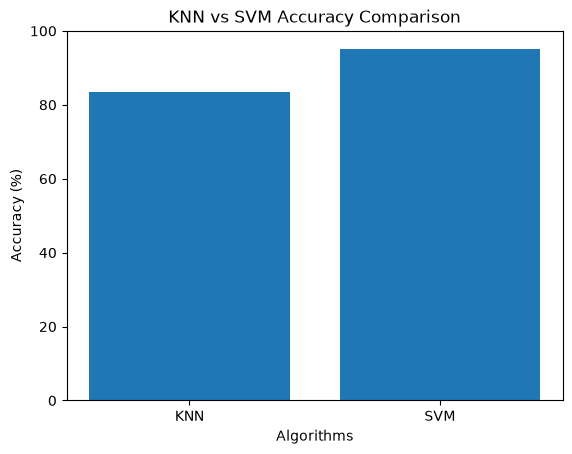

In [13]:
models = ['KNN', 'SVM']
accuracy = [83.38, 95.07]

plt.bar(models, accuracy)
plt.xlabel('Algorithms')
plt.ylabel('Accuracy (%)')
plt.title('KNN vs SVM Accuracy Comparison')
plt.ylim(0, 100)
plt.show()